# VoiceLab starter notebook
AIML ZG520. Keep all outputs. Commit as you work (`!python voicelab.py save "message"`). Parts marked [Critical] must be your own code.

First time only: upload the kit and your `<ROLLNO>_config.json`, then run `!python voicelab.py setup`. Check progress any time with `!python voicelab.py progress`.

In [18]:
# Colab: upload <ROLLNO>_config.json (setup copies it to config.json), voicelab_utils.py and your data/ folder first
import numpy as np, matplotlib.pyplot as plt
from voicelab_utils import *
cfg = load_config('config.json')
set_seed(cfg)
res = Results('results.json')
print(cfg['vocab'])
print(cfg['sentences_spoken'])

['bed', 'bad', 'sink', 'think', 'mat', 'net', 'rice', 'lice', 'pan', 'sheep']
['nine chargers cost five hundred rupees in lucknow', 'remind me to meet anirudh in kochi on thursday', 'call pooja on tuesday morning about the keyboards', 'book three tickets to nagpur for shruti']


## Part 0: Dataset and audit

Three recording blocks: words (30 clips), sentences (4 clips) and room noise (about 11 s). Each block starts with your spoken code, then pauses of 2 s between items.

1. Run the next cell (or `python voicelab.py script`) to print your read-aloud script.
2. Record the three blocks. Save the originals as `data/original/words_block.*`, `sentences_block.*` and `noise_block.*`.
3. Run the cell after that. It converts to 16 kHz mono, splits the clips, audits them and checks your spoken code. Read what it prints: `CHECK` lines name clips to listen to, and `STOPPED` means a block must be recorded again with longer pauses.

In [19]:
recording_script(cfg)

BLOCK 1: WORDS  (record as data/original/words_block.wav)
Silence 1 s, say the code, pause 2 s. Then each line below: say the word once, pause 2 s.
  CODE: 5 5 1 8 3 8
  bed   (repetition 0)
  bed   (repetition 1)
  bed   (repetition 2)
  bad   (repetition 0)
  bad   (repetition 1)
  bad   (repetition 2)
  sink   (repetition 0)
  sink   (repetition 1)
  sink   (repetition 2)
  think   (repetition 0)
  think   (repetition 1)
  think   (repetition 2)
  mat   (repetition 0)
  mat   (repetition 1)
  mat   (repetition 2)
  net   (repetition 0)
  net   (repetition 1)
  net   (repetition 2)
  rice   (repetition 0)
  rice   (repetition 1)
  rice   (repetition 2)
  lice   (repetition 0)
  lice   (repetition 1)
  lice   (repetition 2)
  pan   (repetition 0)
  pan   (repetition 1)
  pan   (repetition 2)
  sheep   (repetition 0)
  sheep   (repetition 1)
  sheep   (repetition 2)

BLOCK 2: SENTENCES  (record as data/original/sentences_block.wav)
Silence 1 s, say the code, pause 2 s. Then each senten

'BLOCK 1: WORDS  (record as data/original/words_block.wav)\nSilence 1 s, say the code, pause 2 s. Then each line below: say the word once, pause 2 s.\n  CODE: 5 5 1 8 3 8\n  bed   (repetition 0)\n  bed   (repetition 1)\n  bed   (repetition 2)\n  bad   (repetition 0)\n  bad   (repetition 1)\n  bad   (repetition 2)\n  sink   (repetition 0)\n  sink   (repetition 1)\n  sink   (repetition 2)\n  think   (repetition 0)\n  think   (repetition 1)\n  think   (repetition 2)\n  mat   (repetition 0)\n  mat   (repetition 1)\n  mat   (repetition 2)\n  net   (repetition 0)\n  net   (repetition 1)\n  net   (repetition 2)\n  rice   (repetition 0)\n  rice   (repetition 1)\n  rice   (repetition 2)\n  lice   (repetition 0)\n  lice   (repetition 1)\n  lice   (repetition 2)\n  pan   (repetition 0)\n  pan   (repetition 1)\n  pan   (repetition 2)\n  sheep   (repetition 0)\n  sheep   (repetition 1)\n  sheep   (repetition 2)\n\nBLOCK 2: SENTENCES  (record as data/original/sentences_block.wav)\nSilence 1 s, say t

In [20]:
# Whole of Part 0 in one command. Run it in a terminal first (it also checks your spoken code with Whisper);
# the options below only repeat the audit when the clips already exist.
!python voicelab.py data --skip-existing --no-whisper

Blocks already converted: skipping conversion.
words: clips already present, skipping the split.
sentences: clips already present, skipping the split.
noise: clips already present, skipping the split.

--- audit
35 files audited (details in data/audit_report.csv).
  no clip was flagged

Spoken-code check skipped (--no-whisper).

PLEASE CONFIRM YOUR RECORDINGS
No clip or block was flagged. Still, listen to a few clips to be sure.

  All recordings OK?    -> continue:  python voicelab.py save "Part 0 data"
                                      python voicelab.py precompute
  Something not OK?     -> record that block again (say every item, pause at least 2 seconds
                           after each), save it over the file in data/original/ and rerun:
                           python voicelab.py data
  A clip that is only a little long, with a breath or extra silence at its edges, is fine.


In [21]:
rows = audit_folder('data')
print_table([r for r in rows if r['clipping_pct'] > 0.5 or r['snr_db'] < 15][:20])  # clips worth a second look

file | duration_s | peak | clipping_pct | snr_db | silence_frac
room_noise.wav | 15.71 | 0.052 | 0.0 | 4.5 | 1.0


## Part 1: Signal analysis and features
TODO: hand DFT (markdown cell), plot a sentence, [Critical] MFCC pipeline, [Critical] F0 by autocorrelation on your sentences.

In [22]:
# [starter] plumbing, not counted as your own code
# Setup for Part 1 (plumbing only). Your front-end settings are in cfg['front_end'].
import glob
fe = cfg['front_end']
words = {w: [f'data/words/{w}_{r}.wav' for r in range(3)] for w in cfg['vocab']}   # 3 repetitions of each word
first_clip = sorted(glob.glob('data/words/*.wav'))[0]                               # the clip for 'mfcc_sum_first_clip'
print(fe)
print('first clip:', first_clip)

{'sr': 16000, 'frame_ms': 25, 'hop_ms': 10, 'window': 'hann', 'n_mels': 26, 'n_mfcc': 12, 'preemph': 0.95, 'lifter': 0, 'delta_N': 2}
first clip: data/words/bad_0.wav


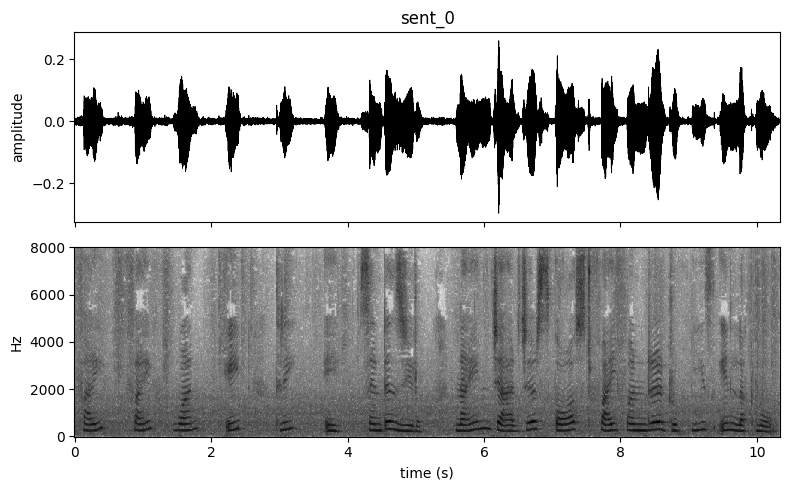

In [23]:
# [starter] plumbing, not counted as your own code
# Spectrogram of a sentence at your sampling rate (a quick helper; use your own STFT if you prefer).
x, fs = load_wav('data/sentences/sent_0.wav', sr=fe['sr'])
plot_wave_spec(x, fs, title='sent_0')
savefig('p1_sent0_spectrogram')      # figures/p1_sent0_spectrogram.png goes into your report
plt.show()

In [24]:
# [Critical] MFCC pipeline: write it yourself with NumPy/SciPy (no librosa.feature.mfcc, no filterbank helper).
# def my_mfcc(x, fs, fe): ...
# mine = my_mfcc(*load_wav(first_clip, sr=fe['sr']), fe)          # shape (frames, n_mfcc)
# Verification only: compare with librosa configured identically, then report the maximum difference per coefficient.
# compare('MFCC vs librosa', mine, librosa_mfcc)
# res.set('mfcc_sum_first_clip', mine.sum())

In [40]:

import numpy as np
from scipy.fft import dct

def my_mfcc(x, fs, fe):
    # 1. Convert audio to floating point
    x = np.asarray(x, dtype=float)

    # 2. Pre-emphasis
    x = np.append(x[0], x[1:] - fe['preemph'] * x[:-1])

    # 3. Frame the signal
    frame_length = int(fe['frame_ms'] * fs / 1000)
    hop_length = int(fe['hop_ms'] * fs / 1000)

    frames = np.array([
        x[i:i + frame_length]
        for i in range(0, len(x) - frame_length + 1, hop_length)
    ])

    # 4. Apply Hann window
    window = np.hanning(frame_length)
    frames = frames * window

    # 5. Calculate power spectrum
    n_fft = 512
    spectrum = np.abs(np.fft.rfft(frames, n=n_fft)) ** 2

    # 6. Create Mel filter bank manually
    def hz_to_mel(hz):
        return 2595 * np.log10(1 + hz / 700)

    def mel_to_hz(mel):
        return 700 * (10 ** (mel / 2595) - 1)

    low_mel = hz_to_mel(0)
    high_mel = hz_to_mel(fs / 2)
    mel_points = np.linspace(low_mel, high_mel, fe['n_mels'] + 2)
    hz_points = mel_to_hz(mel_points)

    bins = np.floor((n_fft + 1) * hz_points / fs).astype(int)
    filters = np.zeros((fe['n_mels'], n_fft // 2 + 1))

    for m in range(1, fe['n_mels'] + 1):
        left = bins[m - 1]
        center = bins[m]
        right = bins[m + 1]

        for k in range(left, center):
            if center > left:
                filters[m - 1, k] = (k - left) / (center - left)

        for k in range(center, right):
            if right > center:
                filters[m - 1, k] = (right - k) / (right - center)

    # 7. Apply Mel filters and logarithm
    mel_energy = np.dot(spectrum, filters.T)
    log_mel = np.log(np.maximum(mel_energy, 1e-10))

    # 8. Apply Discrete Cosine Transform
    mfcc = dct(log_mel, type=2, axis=1, norm='ortho')
    mfcc = mfcc[:, :fe['n_mfcc']]

    # 9. Apply optional liftering
    if fe['lifter'] > 0:
        n = np.arange(fe['n_mfcc'])
        lift = 1 + (fe['lifter'] / 2) * np.sin(np.pi * n / fe['lifter'])
        mfcc = mfcc * lift

    return mfcc


# Calculate MFCC for your first word recording
audio, sample_rate = load_wav(first_clip, sr=fe['sr'])
mine = my_mfcc(audio, sample_rate, fe)

print("MFCC shape:", mine.shape)
print("MFCC sum:", mine.sum())

# Save the required result
res.set('mfcc_sum_first_clip', mine.sum())


MFCC shape: (56, 12)
MFCC sum: -2407.322836948214


In [41]:
print(res.data)

{'mfcc_sum_first_clip': -2407.322836948214}


In [42]:
!python voicelab.py progress

VoiceLab progress  (roll 2025AE05100)
Submission: 28 November (6 days left)
This shows whether the evidence is present, not whether your work is correct.
[x] evidence found   [ ] not yet   [-] you confirm this yourself (not counted)

[x] Set up                                     3/3  done
      [x] your configuration file is present and readable (do not edit it)
      [x] notebook is renamed to voicelab.ipynb
      [x] git repository exists with at least one commit

[x] Part 0. Dataset                            7/7  done
      [x] originals kept in data/original/ (3 files: words, sentences, room noise)
      [x] 3 converted block files in data/blocks/ (16 kHz, mono, 16-bit)
      [x] 30 word clips in data/words/ named word_rep.wav
      [x] 4 sentence clips sent_0.wav to sent_3.wav in data/sentences/
      [x] room noise clip data/noise/room_noise.wav (at least 8 s)
      [x] every clip is 16 kHz, mono, 16-bit
      [x] split reports written (read them for WARNING lines and listen to

In [25]:
# [Critical] F0 by autocorrelation on your sentences: write it yourself.
# savefig('p1_f0_sent0')

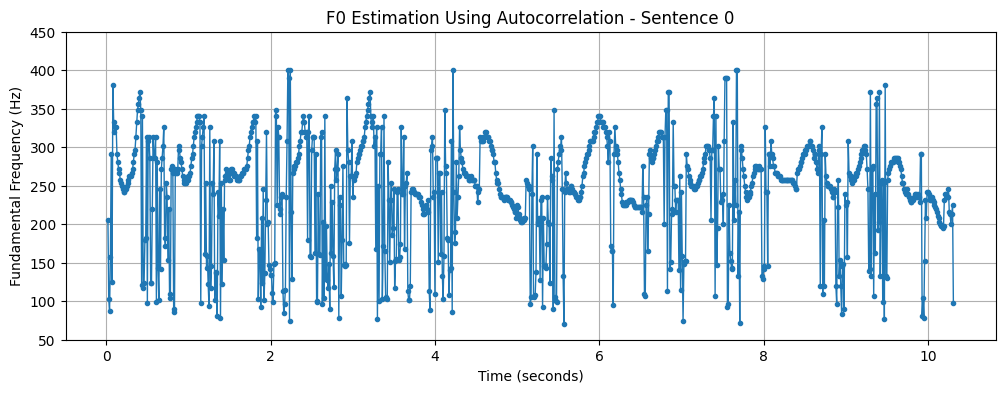

Total frames: 1030
Voiced frames: 1030
Average F0: 242.88129664090363 Hz
Minimum F0: 70.48458149779735 Hz
Maximum F0: 400.0 Hz


In [43]:

import numpy as np
import matplotlib.pyplot as plt

def estimate_f0_autocorrelation(x, fs):

    # Convert audio to NumPy array
    x = np.asarray(x, dtype=float)

    # Remove DC component
    x = x - np.mean(x)

    # Frame settings
    frame_length = int(0.040 * fs)  # 40 milliseconds
    hop_length = int(0.010 * fs)    # 10 milliseconds

    # Expected human voice pitch range
    min_f0 = 70
    max_f0 = 400

    min_lag = int(fs / max_f0)
    max_lag = int(fs / min_f0)

    f0_values = []
    times = []

    # Process audio frame by frame
    for start in range(0, len(x) - frame_length + 1, hop_length):

        frame = x[start:start + frame_length]

        # Apply Hann window
        frame = frame * np.hanning(frame_length)

        # Reject silent frames
        if np.sqrt(np.mean(frame ** 2)) < 0.005:
            f0_values.append(np.nan)
            times.append((start + frame_length / 2) / fs)
            continue

        # Calculate autocorrelation
        correlation = np.correlate(frame, frame, mode='full')
        correlation = correlation[len(frame)-1:]

        # Search for the best pitch lag
        search = correlation[min_lag:max_lag + 1]

        if len(search) == 0 or np.max(search) <= 0:
            f0_values.append(np.nan)

        else:
            best_index = np.argmax(search)
            best_lag = min_lag + best_index

            # Reject unreliable pitch estimates
            if search[best_index] / (correlation[0] + 1e-10) < 0.30:
                f0_values.append(np.nan)
            else:
                f0_values.append(fs / best_lag)

        times.append((start + frame_length / 2) / fs)

    return np.array(times), np.array(f0_values)


# Load first sentence recording
x, fs = load_wav('data/sentences/sent_0.wav', sr=fe['sr'])

# Estimate fundamental frequency
times, f0 = estimate_f0_autocorrelation(x, fs)

# Plot F0 contour
plt.figure(figsize=(12, 4))
plt.plot(times, f0, marker='.', linewidth=1)

plt.xlabel('Time (seconds)')
plt.ylabel('Fundamental Frequency (Hz)')
plt.title('F0 Estimation Using Autocorrelation - Sentence 0')
plt.ylim(50, 450)
plt.grid(True)

# Save figure for report
savefig('p1_f0_sent0')
plt.show()

# Display pitch statistics
valid_f0 = f0[~np.isnan(f0)]

print("Total frames:", len(f0))
print("Voiced frames:", len(valid_f0))

if len(valid_f0) > 0:
    print("Average F0:", np.mean(valid_f0), "Hz")
    print("Minimum F0:", np.min(valid_f0), "Hz")
    print("Maximum F0:", np.max(valid_f0), "Hz")
else:
    print("No reliable voiced frames detected.")


In [26]:
# Save each figure for the report with savefig('name') right after you plot it.
# res.set('mfcc_sum_first_clip', value)  # sum of your own static MFCCs (c0..c_n-1, liftered, no deltas), first clip in data/words

## Part 2: HMM acoustic model
TODO: hand calculation, [Critical] Gaussian emissions, forward, Viterbi, segmental k-means training, evaluation.

In [27]:
# [starter] plumbing, not counted as your own code
# Setup for Part 2 (plumbing only). Training repetitions and the held-out repetition come from your configuration.
held = cfg['hmm']['heldout_rep']
train_files = {w: [p for r, p in enumerate(words[w]) if r != held] for w in cfg['vocab']}
test_files = {w: words[w][held] for w in cfg['vocab']}
print('held-out repetition:', held)
print('states per word model:', cfg['hmm']['states'])
# [Critical] Gaussian emissions, forward, Viterbi, segmental k-means, evaluation: yours.
# Plot the confusion matrix with matplotlib and call savefig('p2_confusion').

held-out repetition: 1
states per word model: 4


In [28]:
# res.set('toy_hmm_forward', value); res.set('toy_hmm_viterbi', value)

## Part 3: CTC
TODO: hand calculation, [Critical] CTC forward algorithm, verify with torch.nn.CTCLoss.

In [29]:
# [Critical] CTC forward algorithm: yours. Check it against torch.nn.CTCLoss (verification only):
# import torch
# loss = torch.nn.CTCLoss(blank=0, reduction='sum')(log_probs, targets, input_lengths, target_lengths)
# compare('CTC forward vs torch', mine_neg_log_prob, loss.item())

In [30]:
# res.set('toy_ctc_prob', value)

## Part 4: Language model and lexicon
TODO: hand calculation, [Critical] Kneser-Ney bigram, lexicon.

In [31]:
sents = brown_sentences()   # Brown corpus as lists of lowercase words. Choose and state your own split.
cmu = cmudict_dict()       # CMUdict {word: [phone lists]}; use g2p_en for words it lacks

In [32]:
# res.set('toy_add1_bigram', value); res.set('toy_kn_bigram', value)

## Part 5: WFST
TODO: hand calculation (determinise, minimise), [Critical] compose() in wfst_starter.py, then L o G for your own words.

In [33]:
# [starter] plumbing, not counted as your own code
from wfst_starter import FST, compose   # FST container and shortest path are given; compose() is yours to write
# [Critical] compose(): implement it in wfst_starter.py, test on small examples, then build L o G for your own words.
print(cfg['vocab'])

['bed', 'bad', 'sink', 'think', 'mat', 'net', 'rice', 'lice', 'pan', 'sheep']


In [34]:
# res.set('wfst_det_states', value)

## Part 6: Recognisers and decoding
TODO: [Critical] WER, wav2vec2 and Whisper outputs, [Critical] CTC prefix beam search with LM fusion, robustness.

The next cell mixes your sentences with your room noise at each SNR in your configuration (`data/noisy/`) and saves the wav2vec2 log posteriors and Whisper text in `cache/`. It needs internet the first time and takes a few minutes on CPU. Computing WER, grouping the errors, the beam search and the plots are yours.

In [35]:
!python voicelab.py precompute --if-missing
transcripts = load_transcripts()                    # Whisper text, e.g. transcripts['sent_0_clean']
logp, tokens = load_posteriors('sent_0_clean')      # wav2vec2 log posteriors (T x V) and the token list

Model steps run on: cpu
Mixed noisy versions of your 4 sentences at SNR [15, 5] dB (data/noisy/).

Saved in cache/: log posteriors (load_posteriors('sent_0_clean')) and Whisper text (load_transcripts()). They are the model outputs only; WER, grouping and beam search are yours.


In [36]:
# [starter] plumbing, not counted as your own code
# Names of the cached outputs: clean sentences and each noise level in your configuration.
refs = cfg['sentences_spoken']                                  # reference text for WER
names = [f'sent_{i}_clean' for i in range(len(refs))] + [f'sent_{i}_snr{s}' for i in range(len(refs)) for s in cfg['noise']['snr_db']]
print(names[:6], '...')
print('beam widths:', cfg['decoding']['beam_widths'])
# [Critical] WER (edit-distance DP), CTC prefix beam search with LM fusion, error analysis: yours.
# jiwer is allowed only to verify your WER: compare('WER vs jiwer', mine, jiwer.wer(ref, hyp))

['sent_0_clean', 'sent_1_clean', 'sent_2_clean', 'sent_3_clean', 'sent_0_snr15', 'sent_0_snr5'] ...
beam widths: [1, 8]


In [37]:
# res.set('wer_sentence1_wav2vec2', value); res.set('wer_widest_beam', value)

## Part 7: Speech synthesis
TODO: [Critical] text normaliser, [Critical] Griffin-Lim, pretrained TTS (tts_synthesise), STOI (stoi_score).

In [38]:
# [starter] plumbing, not counted as your own code
# Setup for Part 7 (plumbing only). The TTS model is fixed by your configuration.
tts_name = cfg['tts']['torchaudio_pipeline']
text0 = cfg['sentences_spoken'][0]
# Neural TTS takes about a minute per sentence on a CPU; uncomment when you are ready.
# wav_tts, fs_tts = tts_synthesise(text0, tts_name)
# import soundfile as sf; sf.write('figures/tts_sent0.wav', wav_tts, fs_tts)
# STOI (verification metric): stoi_score(reference, degraded, fs) with both signals at the same sampling rate
# [Critical] text normaliser and Griffin-Lim: yours. Spectral convergence after 30 iterations -> res.set('griffinlim_convergence_30', value)

In [39]:
# res.set('griffinlim_convergence_30', value)

## Finish
Run `!python voicelab.py progress` for what is left. Then `python voicelab.py handwork` (photos in `handwork/`), `python voicelab.py report`, and `python voicelab.py package` once the notebook is run with outputs kept.